# Importing libraries

In [108]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier, plot_tree

#Loading the data

In [109]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [110]:
datapath='/content/drive/MyDrive/dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv'
df=pd.read_csv(datapath)

#EDA

In [111]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


#

In [112]:
df.shape

(7043, 21)

In [113]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [114]:
df.head(2)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No


In [115]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [116]:
pd.set_option('display.max_columns',None)

In [117]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [118]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [119]:
df.duplicated().sum()

np.int64(0)

In [120]:
for col in df.columns:
    print(col, df[col].unique())

customerID ['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']
gender ['Female' 'Male']
SeniorCitizen [0 1]
Partner ['Yes' 'No']
Dependents ['No' 'Yes']
tenure [ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30 47 72 17 27
  5 46 11 70 63 43 15 60 18 66  9  3 31 50 64 56  7 42 35 48 29 65 38 68
 32 55 37 36 41  6  4 33 67 23 57 61 14 20 53 40 59 24 44 19 54 51 26  0
 39]
PhoneService ['No' 'Yes']
MultipleLines ['No phone service' 'No' 'Yes']
InternetService ['DSL' 'Fiber optic' 'No']
OnlineSecurity ['No' 'Yes' 'No internet service']
OnlineBackup ['Yes' 'No' 'No internet service']
DeviceProtection ['No' 'Yes' 'No internet service']
TechSupport ['No' 'Yes' 'No internet service']
StreamingTV ['No' 'Yes' 'No internet service']
StreamingMovies ['No' 'Yes' 'No internet service']
Contract ['Month-to-month' 'One year' 'Two year']
PaperlessBilling ['Yes' 'No']
PaymentMethod ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (a

In [121]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")


In [122]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


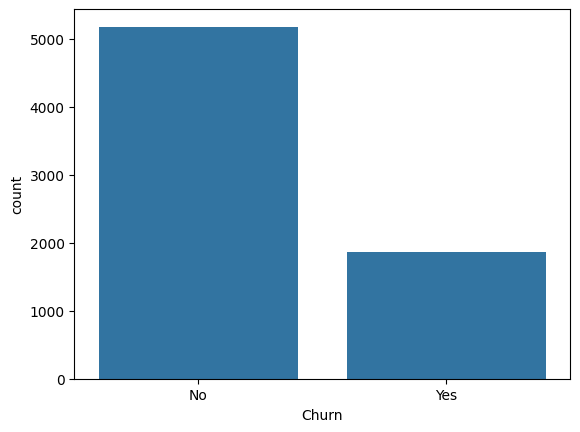

In [123]:
sns.countplot(x="Churn", data=df)
plt.show()

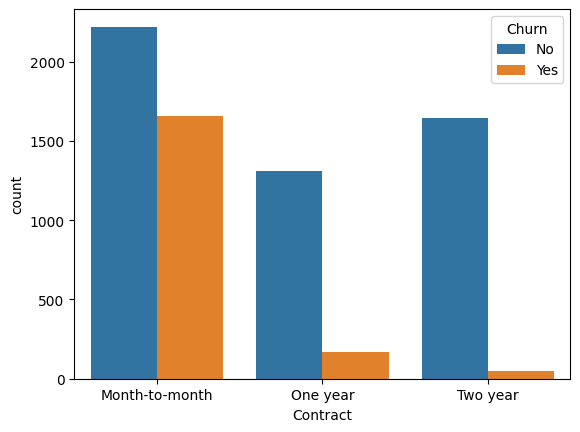

In [124]:
sns.countplot(x="Contract", hue="Churn", data=df)
plt.show()

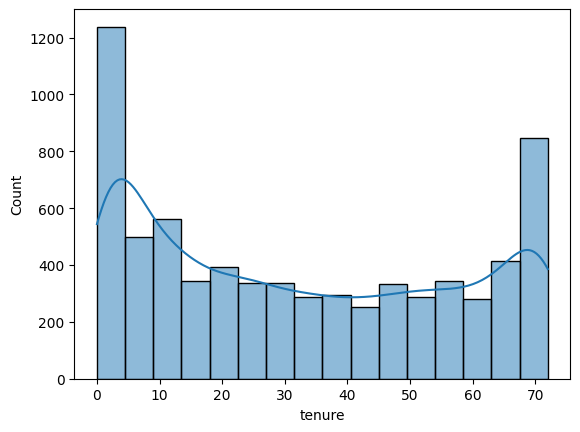

In [125]:
sns.histplot(df["tenure"], kde=True)
plt.show()

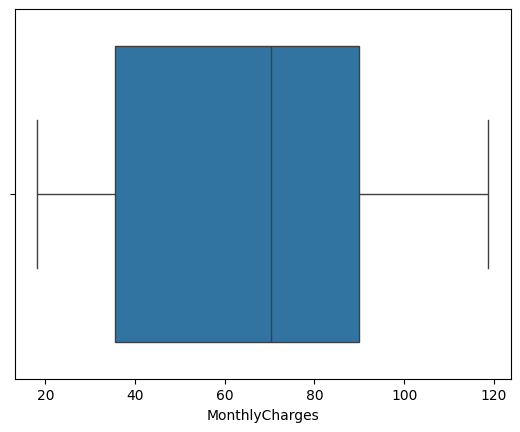

In [126]:
sns.boxplot(x=df["MonthlyCharges"])
plt.show()

In [127]:
df = df.drop_duplicates()
df = df.drop("customerID", axis=1)

In [128]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

In [129]:
y = y.map({"No": 0, "Yes": 1})

In [130]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y
)

In [131]:
X_train.isnull().sum()

,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


In [132]:
X_test.isnull().sum()

,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


In [133]:
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns

cat_cols = X_train.select_dtypes(include=['object']).columns

print("Numerical Columns:")
print(list(num_cols))

print("\nCategorical Columns:")
print(list(cat_cols))

Numerical Columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [134]:

for col in num_cols:
    X_train[col] = X_train[col].fillna(X_train[col].median())
    X_test[col] = X_test[col].fillna(X_train[col].median())
#Median imputation was used for numerical columns because it is less affected by outliers.

In [135]:
for col in cat_cols:
    X_train[col] = X_train[col].fillna(X_train[col].mode()[0])
    X_test[col] = X_test[col].fillna(X_train[col].mode()[0])
#Mode imputation was used for categorical columns because it replaces missing values with the most frequently occurring category.

In [136]:
one_hot_encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown='ignore',
    drop='first'
)

X_train_encoded = one_hot_encoder.fit_transform(X_train[cat_cols])

X_test_encoded = one_hot_encoder.transform(X_test[cat_cols])

### One-Hot Encoding

One-Hot Encoding was applied to convert categorical variables into numerical format so that machine learning algorithms can process them. It creates separate binary columns for each category. The first category was dropped to avoid redundant features.

In [137]:
X_train_encoded = pd.DataFrame(
    X_train_encoded,
    columns=one_hot_encoder.get_feature_names_out(cat_cols),
    index=X_train.index
)

X_test_encoded = pd.DataFrame(
    X_test_encoded,
    columns=one_hot_encoder.get_feature_names_out(cat_cols),
    index=X_test.index
)

In [138]:
X_train_final = pd.concat(
    [X_train[num_cols], X_train_encoded],
    axis=1
)

X_test_final = pd.concat(
    [X_test[num_cols], X_test_encoded],
    axis=1
)

In [139]:
outlier_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

for col in outlier_cols:
    Q1 = X_train_final[col].quantile(0.25)
    Q3 = X_train_final[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    X_train_final[col] = X_train_final[col].clip(lower, upper)
    X_test_final[col] = X_test_final[col].clip(lower, upper)

In [140]:
scaler = StandardScaler()

X_train_final[num_cols] = scaler.fit_transform(
    X_train_final[num_cols]
)

X_test_final[num_cols] = scaler.transform(
    X_test_final[num_cols]
)

### Feature Scaling

StandardScaler was used to bring numerical features to a similar scale. It transforms the data to have a mean of 0 and a standard deviation of 1. Scaling is important for distance-based algorithms like KNN and helps Logistic Regression perform effectively.

In [141]:
smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_final, y_train
)

### Handling Class Imbalance using SMOTE

The target variable contains an imbalance between customers who churn and those who do not churn. SMOTE (Synthetic Minority Over-sampling Technique) was applied to generate synthetic samples of the minority class. This helps the model learn patterns from both classes more effectively.

In [142]:
print("Training shape:", X_train_balanced.shape)
print("Testing shape:", X_test_final.shape)

print("\nClass distribution after SMOTE:")
print(y_train_balanced.value_counts())

Training shape: (8278, 30)
Testing shape: (1409, 30)

Class distribution after SMOTE:
Churn
0    4139
1    4139
Name: count, dtype: int64


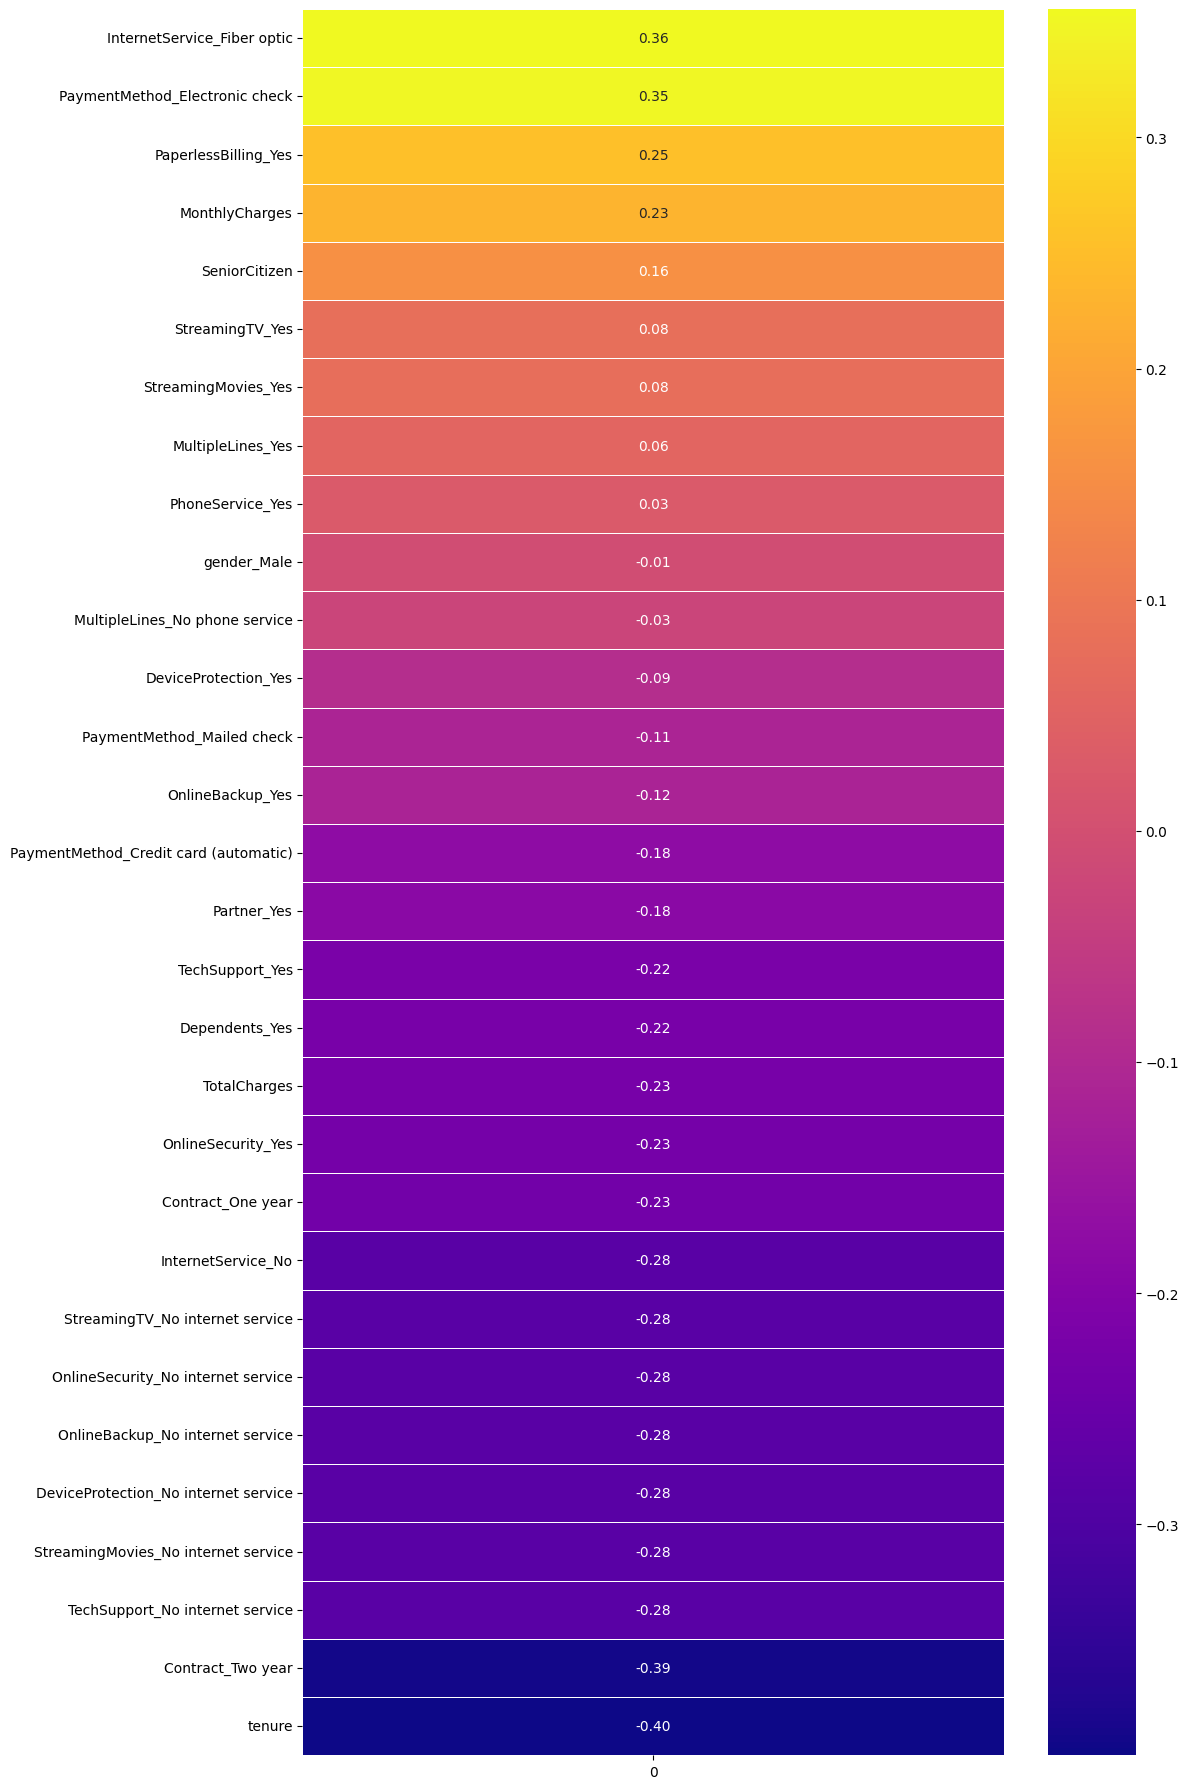

In [143]:
corr = X_train_balanced.corrwith(y_train_balanced).sort_values(ascending=False).to_frame()

plt.figure(figsize=(12,18))

sns.heatmap(
    corr,
    cmap='plasma',
    annot=True,
    linewidth=.5,
    fmt=".2f"
)

plt.tight_layout()
plt.show()

### Feature Selection

Feature selection was performed to identify the most relevant features for predicting customer churn. It helps reduce unnecessary features, simplify the model and improve model performance. The selected features were based on correlation and their relevance to the target variable.

In [144]:
selected_features = ['tenure', 'Contract_Two year']

X_train_selected = X_train_balanced[selected_features]
X_test_selected = X_test_final[selected_features]

### Logistic Regression

Logistic Regression was selected because customer churn is a binary classification problem with two possible outcomes: Yes or No. It uses the sigmoid function to estimate the probability of a customer leaving and classifies the result based on a decision threshold.

In [165]:
log_reg = LogisticRegression()

log_reg.fit(X_train_selected, y_train_balanced)

LogisticRegression()

#Logistic Regression – Threshold Tuning
using predict_proba() to obtain churn probabilities and testing different thresholds (0.3, 0.5, and 0.7). This helps me understand how changing the threshold affects precision and recall.

In [166]:
lr_train_pred = log_reg.predict(X_train_selected)

lr_prob = log_reg.predict_proba(X_test_selected)[:, 1]

lr_test_pred = (lr_prob >= 0.5).astype(int)

#Accuracy score - log reg

In [167]:
lr_train_acc = accuracy_score(y_train_balanced, lr_train_pred)

lr_test_acc = accuracy_score(y_test, lr_test_pred)

print("Training Accuracy:", lr_train_acc)
print("Testing Accuracy:", lr_test_acc)

Training Accuracy: 0.6791495530321333
Testing Accuracy: 0.6330731014904187


### Logistic Regression – Threshold Comparison

Logistic Regression uses predict_proba() to calculate the probability of customer churn. Different decision thresholds (0.3, 0.5 and 0.7) were tested to understand their impact on classification results.

A lower threshold predicts more customers as likely to churn, which generally increases recall.

A higher threshold predicts fewer customers as likely to churn, which generally increases precision.


In [168]:
thresholds = [0.3, 0.5, 0.7]

for threshold in thresholds:

    lr_threshold_pred = (lr_prob >= threshold).astype(int)

    print("Threshold:", threshold)

    print("Accuracy:", accuracy_score(y_test, lr_threshold_pred))

    print(classification_report(y_test, lr_threshold_pred))

Threshold: 0.3
Accuracy: 0.49396735273243436
              precision    recall  f1-score   support

           0       0.97      0.32      0.48      1035
           1       0.34      0.98      0.51       374

    accuracy                           0.49      1409
   macro avg       0.66      0.65      0.49      1409
weighted avg       0.81      0.49      0.49      1409

Threshold: 0.5
Accuracy: 0.6330731014904187
              precision    recall  f1-score   support

           0       0.91      0.56      0.69      1035
           1       0.41      0.84      0.55       374

    accuracy                           0.63      1409
   macro avg       0.66      0.70      0.62      1409
weighted avg       0.77      0.63      0.65      1409

Threshold: 0.7
Accuracy: 0.765791341376863
              precision    recall  f1-score   support

           0       0.80      0.91      0.85      1035
           1       0.60      0.36      0.45       374

    accuracy                           0.77      1

#confusion matrix - log reg
using a confusion matrix to identify correct and incorrect predictions made by the model, including false positives and false negatives.

In [169]:
cm = confusion_matrix(y_test, lr_test_pred)

print(cm)

[[577 458]
 [ 59 315]]


#heatmap

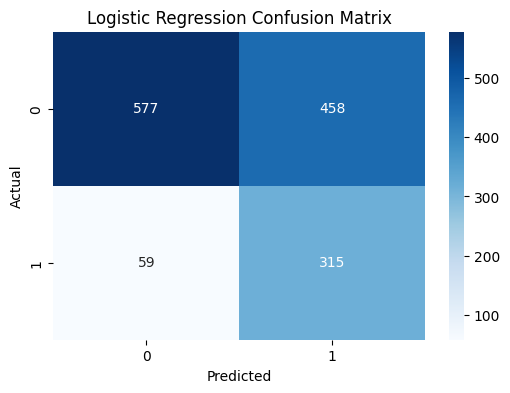

In [170]:
plt.figure(figsize=(6, 4))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [171]:
tn, fp, fn, tp = cm.ravel()

print("True Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive:", tp)

True Negative: 577
False Positive: 458
False Negative: 59
True Positive: 315


In [148]:
# lr_train_pred=log_reg.predict(X_train_selected)
# lr_test_pred=log_reg.predict(X_test_selected)

In [149]:
# lr_train_acc=accuracy_score(y_train_balanced,lr_train_pred)
# lr_test_acc=accuracy_score(y_test,lr_test_pred)

# print("Training Accuracy:",lr_train_acc)
# print("Testing Accuracy:",lr_test_acc)

### K-Nearest Neighbors (KNN)

KNN was selected as another classification algorithm to compare its performance with Logistic Regression. It classifies a customer based on the majority class among its nearest neighbors. Different K values were tested to identify the optimal value using the validation F1-score.

In [172]:
knn = KNeighborsClassifier(n_neighbors=4)

knn.fit(X_train_selected, y_train_balanced)

KNeighborsClassifier(n_neighbors=4)

#KNN prediction

In [173]:
knn_train_pred = knn.predict(X_train_selected)

knn_test_pred = knn.predict(X_test_selected)

#KNN accuracy score

In [177]:
knn_train_acc = accuracy_score(y_train_balanced, knn_train_pred)

knn_test_acc = accuracy_score(y_test, knn_test_pred)

print("Training Accuracy:", knn_train_acc)
print("Testing Accuracy:", knn_test_acc)

Training Accuracy: 0.7350809374244986
Testing Accuracy: 0.7132718239886444


#KNN confusion matrix

In [178]:
cm_knn = confusion_matrix(y_test, knn_test_pred)

print(cm_knn)

[[974  61]
 [343  31]]


#KNN classification report

In [179]:
print(classification_report(y_test, knn_test_pred))

              precision    recall  f1-score   support

           0       0.74      0.94      0.83      1035
           1       0.34      0.08      0.13       374

    accuracy                           0.71      1409
   macro avg       0.54      0.51      0.48      1409
weighted avg       0.63      0.71      0.64      1409



#Heatmap

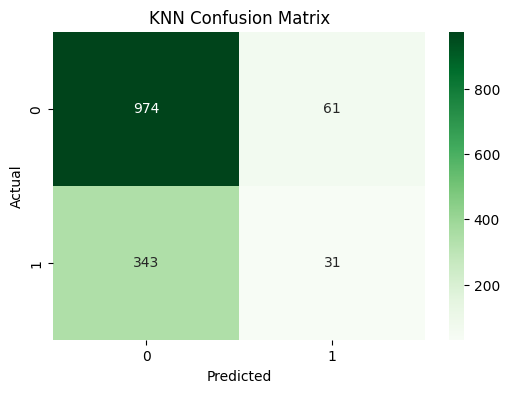

In [180]:
plt.figure(figsize=(6, 4))

sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Greens')

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

### False Positive and False Negative Analysis

In customer churn prediction:

- False Positive (FP): The model predicts that a customer will churn, but the customer actually stays. This may lead to unnecessary retention offers or discounts.

- False Negative (FN): The model predicts that a customer will stay, but the customer actually churns. This may result in losing a customer without taking preventive action.

False negatives are particularly important in churn prediction because identifying customers who are likely to leave helps businesses take early retention measures.

#Decision Tree Classifier
The algorithm creates decision rules based on the input features to classify customers into churn and non-churn categories.

In [181]:
dt3 = DecisionTreeClassifier(max_depth=3, random_state=42)

dt3.fit(X_train_selected, y_train_balanced)

dt3_pred = dt3.predict(X_test_selected)

dt3_acc = accuracy_score(y_test, dt3_pred)

dt3_precision = precision_score(y_test, dt3_pred, zero_division=0)

dt3_recall = recall_score(y_test, dt3_pred, zero_division=0)

dt3_f1 = f1_score(y_test, dt3_pred, zero_division=0)

print("Accuracy:", dt3_acc)
print("Precision:", dt3_precision)
print("Recall:", dt3_recall)
print("F1 Score:", dt3_f1)

Accuracy: 0.7288857345635202
Precision: 0.491869918699187
Recall: 0.6470588235294118
F1 Score: 0.558891454965358


### Effect of Maximum Tree Depth

The Decision Tree is trained with different max_depth values (3, 5, 10, and None). The resulting performance scores are compared to understand how tree complexity affects model performance.

In [182]:
dt5 = DecisionTreeClassifier(max_depth=5, random_state=42)

dt5.fit(X_train_selected, y_train_balanced)

dt5_pred = dt5.predict(X_test_selected)

dt5_acc = accuracy_score(y_test, dt5_pred)

dt5_precision = precision_score(y_test, dt5_pred, zero_division=0)

dt5_recall = recall_score(y_test, dt5_pred, zero_division=0)

dt5_f1 = f1_score(y_test, dt5_pred, zero_division=0)

print("Accuracy:", dt5_acc)
print("Precision:", dt5_precision)
print("Recall:", dt5_recall)
print("F1 Score:", dt5_f1)

Accuracy: 0.7288857345635202
Precision: 0.491869918699187
Recall: 0.6470588235294118
F1 Score: 0.558891454965358


In [183]:
dt10 = DecisionTreeClassifier(max_depth=10, random_state=42)

dt10.fit(X_train_selected, y_train_balanced)

dt10_pred = dt10.predict(X_test_selected)

dt10_acc = accuracy_score(y_test, dt10_pred)

dt10_precision = precision_score(y_test, dt10_pred, zero_division=0)

dt10_recall = recall_score(y_test, dt10_pred, zero_division=0)

dt10_f1 = f1_score(y_test, dt10_pred, zero_division=0)

print("Accuracy:", dt10_acc)
print("Precision:", dt10_precision)
print("Recall:", dt10_recall)
print("F1 Score:", dt10_f1)

Accuracy: 0.7047551454932577
Precision: 0.4602272727272727
Recall: 0.6497326203208557
F1 Score: 0.5388026607538803


In [184]:
dt_none = DecisionTreeClassifier(max_depth=None, random_state=42)

dt_none.fit(X_train_selected, y_train_balanced)

dt_none_pred = dt_none.predict(X_test_selected)

dt_none_acc = accuracy_score(y_test, dt_none_pred)

dt_none_precision = precision_score(y_test, dt_none_pred, zero_division=0)

dt_none_recall = recall_score(y_test, dt_none_pred, zero_division=0)

dt_none_f1 = f1_score(y_test, dt_none_pred, zero_division=0)

print("Accuracy:", dt_none_acc)
print("Precision:", dt_none_precision)
print("Recall:", dt_none_recall)
print("F1 Score:", dt_none_f1)

Accuracy: 0.7672107877927609
Precision: 0.5804195804195804
Recall: 0.44385026737967914
F1 Score: 0.503030303030303


### Decision Tree Model Evaluation

The Decision Tree model is evaluated using accuracy, precision, recall, and F1-score. A confusion matrix is also generated to examine its classification performance.

In [185]:
dt_comparison = pd.DataFrame({

    'Max Depth': ['3', '5', '10', 'None'],

    'Accuracy': [dt3_acc, dt5_acc, dt10_acc, dt_none_acc],

    'Precision': [dt3_precision, dt5_precision, dt10_precision, dt_none_precision],

    'Recall': [dt3_recall, dt5_recall, dt10_recall, dt_none_recall],

    'F1 Score': [dt3_f1, dt5_f1, dt10_f1, dt_none_f1]

})

dt_comparison

,Max Depth,Accuracy,Precision,Recall,F1 Score
0,3,0.728886,0.491870,0.647059,0.558891
1,5,0.728886,0.491870,0.647059,0.558891
2,10,0.704755,0.460227,0.649733,0.538803
3,None,0.767211,0.580420,0.443850,0.503030


### Decision Tree Visualization

The trained Decision Tree is visualized to understand the decision-making process, feature-based splits, and classification outcomes at each node.

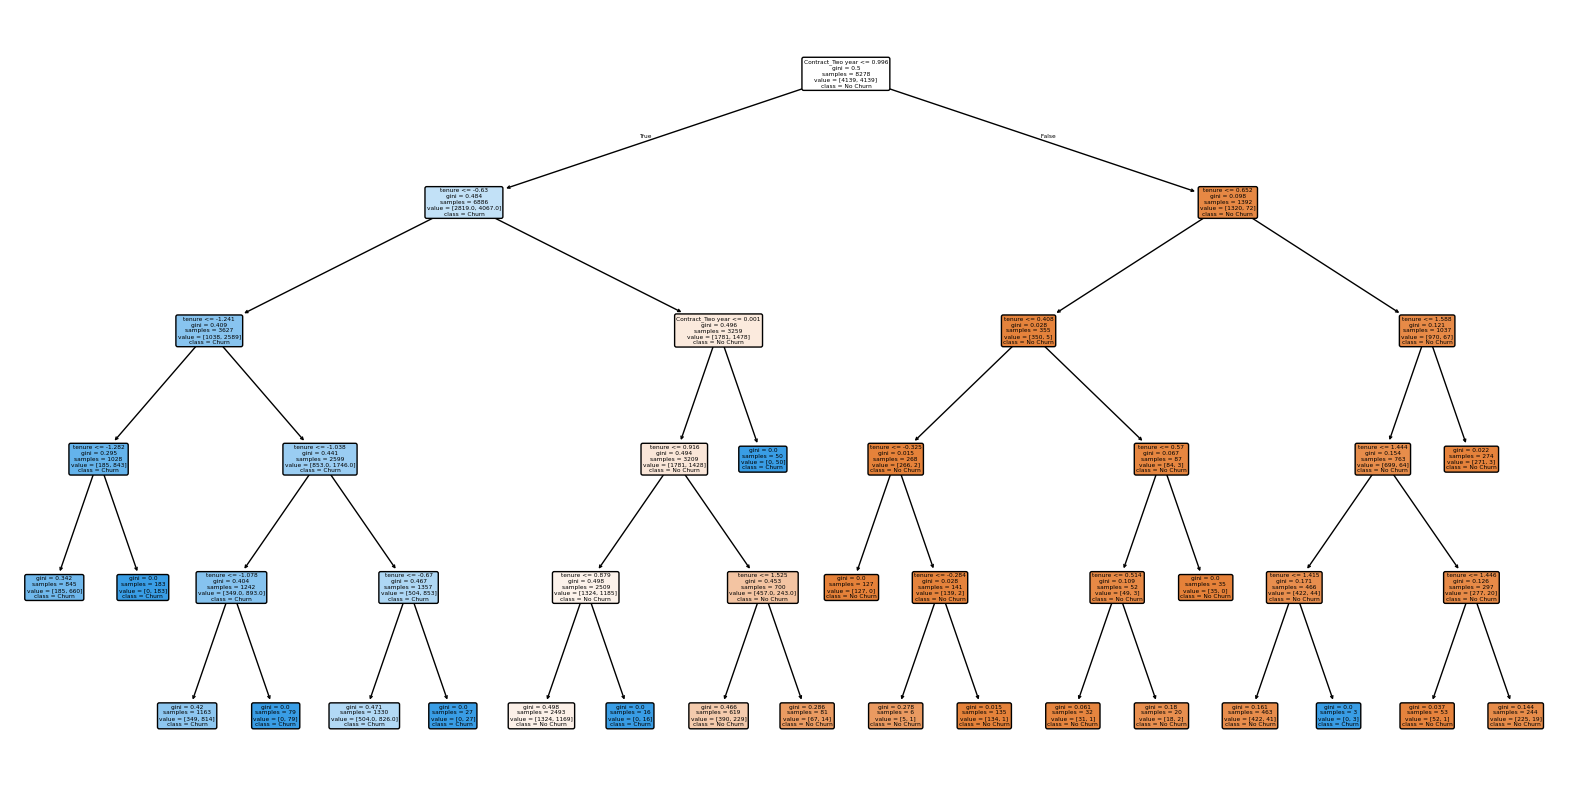

In [186]:
plt.figure(figsize=(20, 10))

plot_tree(
    dt5,
    feature_names=X_train_selected.columns,
    class_names=['No Churn', 'Churn'],
    filled=True,
    rounded=True
)

plt.show()

In [187]:
cm_dt = confusion_matrix(y_test, dt5_pred)

print(cm_dt)

[[785 250]
 [132 242]]


In [188]:
print(classification_report(y_test, dt5_pred))

              precision    recall  f1-score   support

           0       0.86      0.76      0.80      1035
           1       0.49      0.65      0.56       374

    accuracy                           0.73      1409
   macro avg       0.67      0.70      0.68      1409
weighted avg       0.76      0.73      0.74      1409



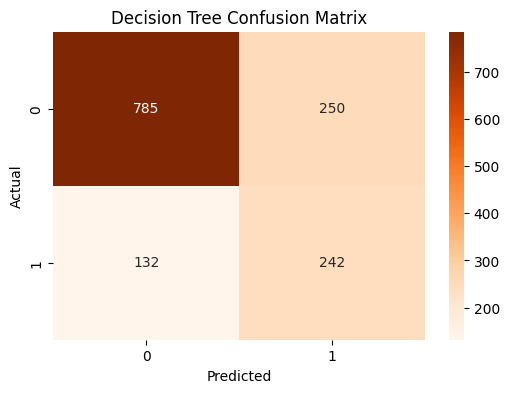

In [189]:
plt.figure(figsize=(6, 4))

sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Oranges')

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [191]:
model_comparison = pd.DataFrame({

    'Model': ['Logistic Regression', 'KNN', 'Decision Tree'],

    'Accuracy': [
        accuracy_score(y_test, lr_test_pred),
        accuracy_score(y_test, knn_test_pred),
        accuracy_score(y_test, dt5_pred)
    ],

    'Precision': [
        precision_score(y_test, lr_test_pred, zero_division=0),
        precision_score(y_test, knn_test_pred, zero_division=0),
        precision_score(y_test, dt5_pred, zero_division=0)
    ],

    'Recall': [
        recall_score(y_test, lr_test_pred, zero_division=0),
        recall_score(y_test, knn_test_pred, zero_division=0),
        recall_score(y_test, dt5_pred, zero_division=0)
    ],

    'F1 Score': [
        f1_score(y_test, lr_test_pred, zero_division=0),
        f1_score(y_test, knn_test_pred, zero_division=0),
        f1_score(y_test, dt5_pred, zero_division=0)
    ]

})

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.633073,0.407503,0.842246,0.549259
1,KNN,0.713272,0.336957,0.082888,0.133047
2,Decision Tree,0.728886,0.491870,0.647059,0.558891


Among the 3 models, Decision Tree achieved the highest accuracy of 72.89% and the highest F1-score of 55.89%. It also achieved the highest precision of 49.19%, with a recall of 64.71%.

Although Logistic Regression achieved a higher recall of 84.22%, Decision Tree provides a better overall balance between precision and recall.

KNN performed poorly in identifying churn customers, achieving only 8.29% recall.

Therefore, Decision Tree is recommended as the best-performing model among the three for this customer churn prediction task